# 07 -- Final comparison
6 methods x 4 data sizes x 5 seeds. Pure analysis over what the method notebooks logged

Statistics use **paired differences by seed** (same seed and data size for FFT and the PEFT method). With 5 seeds the
exact Wilcoxon test cannot go below p = 0.0625, so it is shown for completeness only; the paired t-test, its Holm-adjusted
p-value and the 95% confidence interval of the mean difference are the numbers to report. Effect sizes (Cohen's d) are
deliberately not reported: with this few seeds they blow up whenever the seed-to-seed spread is small.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RESULTS_PATH = "/content/drive/MyDrive/thesis/results.csv"
PREDICTIONS_PATH = "/content/drive/MyDrive/thesis/predictions.csv"
LOGS_DIR = "/content/drive/MyDrive/thesis/logs"
FIGURES_DIR = "/content/drive/MyDrive/thesis/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

METHODS = ["FFT", "LoRA", "BitFit", "IA3", "Houlsby", "Pfeiffer"]
SEEDS = [42, 123, 456, 789, 2026]
SIZES = [5, 10, 50, 100]

# Which configuration (tag) of each method is the "final" one. Change a method's tag
# here after an LR check, e.g. TAG_FOR_METHOD["BitFit"] = "lr_final".
TAG_FOR_METHOD = {m: "main" for m in METHODS}

MARKERS = {"FFT": "o", "LoRA": "s", "BitFit": "^", "IA3": "D", "Houlsby": "v", "Pfeiffer": "P"}
LINESTYLES = {"FFT": "-", "LoRA": "--", "BitFit": "-.", "IA3": ":",
              "Houlsby": (0, (5, 1)), "Pfeiffer": (0, (3, 1, 1, 1))}
HATCHES = {"FFT": "", "LoRA": "//", "BitFit": "\\\\", "IA3": "..", "Houlsby": "xx", "Pfeiffer": "++"}
COLORS = {"FFT": "#2a78d6", "LoRA": "#008300", "BitFit": "#e87ba4",
          "IA3": "#eda100", "Houlsby": "#1baf7a", "Pfeiffer": "#eb6834"}
ID2LABEL = {0: "fact", 1: "hoax"}

def run_key(method, size, seed, tag):
    return f"{method}_{tag}_s{int(size)}_{int(seed)}"

def savefig(fig, name):
    fig.savefig(f"{FIGURES_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(f"{FIGURES_DIR}/{name}.pdf", bbox_inches="tight")
    print(f"saved {name}.png / .pdf")

Mounted at /content/drive


### Load results (final tag per method)

In [3]:
raw = pd.read_csv(RESULTS_PATH)
if "data_size" not in raw.columns:
    raise RuntimeError("results.csv is in the old layout -- run 00_Setup_and_Migration.ipynb first")

keep = pd.Series(False, index=raw.index)
for m, t in TAG_FOR_METHOD.items():
    keep |= (raw["method"] == m) & (raw["tag"] == t)
results = raw[keep & raw["data_size"].isin(SIZES) & raw["seed"].isin(SEEDS)].copy()

pred_raw = pd.read_csv(PREDICTIONS_PATH)
pk = pd.Series(False, index=pred_raw.index)
for m, t in TAG_FOR_METHOD.items():
    pk |= (pred_raw["method"] == m) & (pred_raw["tag"] == t)
predictions = pred_raw[pk & pred_raw["data_size"].isin(SIZES) & pred_raw["seed"].isin(SEEDS)].copy()

print(f"{len(results)} result rows, {len(predictions):,} prediction rows (final tags only)")

120 result rows, 291,120 prediction rows (final tags only)


### Completeness check
Expects every (method, data size, seed) cell: 6 methods * 4 sizes * 5 seeds = 120 runs.

In [4]:
expected = {(m, s, sd) for m in METHODS for s in SIZES for sd in SEEDS}
actual = set(zip(results["method"], results["data_size"], results["seed"]))
missing = sorted(expected - actual)
print(f"Expected {len(expected)} runs | found {len(actual)}")
if missing:
    print(f"MISSING {len(missing)}:")
    for m, s, sd in missing:
        print(f"  - {m} | {s}% | seed {sd}")
else:
    print("All runs present.")

dupes = results[results.duplicated(subset=["method", "data_size", "seed"], keep=False)]
print("Duplicate (method, size, seed) rows:", len(dupes))

gpus = results.groupby("method")["gpu"].unique()
print()
print("GPU types per method (should be one type throughout):")
print(gpus.to_string())

Expected 120 runs | found 120
All runs present.
Duplicate (method, size, seed) rows: 0

GPU types per method (should be one type throughout):
method
BitFit      [Tesla T4]
FFT         [Tesla T4]
Houlsby     [Tesla T4]
IA3         [Tesla T4]
LoRA        [Tesla T4]
Pfeiffer    [Tesla T4]


## Summary tables
Mean +/- std over seeds. `pct_of_fft_f1` and `params_reduction_x` are relative to FFT *at the same data size*.

In [5]:
def summarize(df):
    g = df.groupby(["data_size", "method"])
    s = g.agg(
        n_seeds=("seed", "count"),
        val_f1_mean=("best_val_f1", "mean"), val_f1_std=("best_val_f1", "std"),
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
        prec_mean=("precision", "mean"), prec_std=("precision", "std"),
        rec_mean=("recall", "mean"), rec_std=("recall", "std"),
        f1_mean=("f1", "mean"), f1_std=("f1", "std"),
        trainable_params=("trainable_params", "first"),
        trainable_pct=("trainable_pct", "first"),
        vram_mean=("peak_vram_gb", "mean"), vram_std=("peak_vram_gb", "std"),
        time_mean_min=("total_time_s", lambda x: x.mean() / 60),
        steps_mean=("steps_run", "mean"),
    )
    s["macro_f1_mean"] = s["f1_mean"]
    s["macro_f1_std"] = s["f1_std"]
    s["sec_per_step"] = s["time_mean_min"] * 60 / s["steps_mean"]
    s["sec_per_531_steps"] = s["sec_per_step"] * 531
    s = s.reindex(pd.MultiIndex.from_product([SIZES, METHODS], names=["data_size", "method"]))
    s["val_test_gap"] = s["val_f1_mean"] - s["f1_mean"]
    sizes_idx = s.index.get_level_values("data_size")
    fft = s.xs("FFT", level="method")
    s["pct_of_fft_f1"] = 100 * s["f1_mean"] / sizes_idx.map(fft["f1_mean"])
    s["params_reduction_x"] = sizes_idx.map(fft["trainable_params"]) / s["trainable_params"]
    return s

summary = summarize(results)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("=== 100% of training data ===")
summary.loc[100]

=== 100% of training data ===


,n_seeds,val_f1_mean,val_f1_std,acc_mean,acc_std,prec_mean,prec_std,rec_mean,rec_std,f1_mean,...,vram_std,time_mean_min,steps_mean,macro_f1_mean,macro_f1_std,sec_per_step,sec_per_531_steps,val_test_gap,pct_of_fft_f1,params_reduction_x
method,,,,,,,,,,,,,,,,,,,,,
FFT,5,0.9340,0.0038,0.9218,0.0039,0.9219,0.0039,0.9218,0.0039,0.9218,...,0.0008,8.8633,4141.8000,0.9218,0.0039,0.1284,68.1795,0.0121,100.0000,1.0000
LoRA,5,0.9241,0.0043,0.9126,0.0050,0.9129,0.0049,0.9126,0.0050,0.9126,...,0.0004,4.5570,4354.2000,0.9126,0.0050,0.0628,33.3439,0.0115,98.9971,419.7770
BitFit,5,0.9082,0.0081,0.9088,0.0047,0.9094,0.0045,0.9088,0.0047,0.9088,...,0.0000,9.4713,6372.0000,0.9088,0.0047,0.0892,47.3567,-0.0006,98.5840,1191.4110
IA3,5,0.9265,0.0038,0.9127,0.0027,0.9129,0.0028,0.9127,0.0027,0.9127,...,0.0000,4.7993,4991.4000,0.9127,0.0027,0.0577,30.6340,0.0139,99.0067,2189.5851
Houlsby,5,0.9267,0.0053,0.9171,0.0043,0.9175,0.0042,0.9171,0.0043,0.9170,...,0.0000,7.2680,4672.8000,0.9170,0.0043,0.0933,49.5545,0.0097,99.4793,52.2693
Pfeiffer,5,0.9317,0.0032,0.9191,0.0023,0.9193,0.0021,0.9191,0.0023,0.9191,...,0.0004,9.4170,5416.2000,0.9191,0.0023,0.1043,55.3941,0.0125,99.7043,104.4711


In [6]:
print("Test F1 (mean) by data size:")
summary["f1_mean"].unstack("data_size")[SIZES].reindex(METHODS)

Test F1 (mean) by data size:


data_size,5,10,50,100
method,,,,
FFT,0.8498,0.8678,0.9129,0.9218
LoRA,0.8458,0.8620,0.9036,0.9126
BitFit,0.8574,0.8663,0.8972,0.9088
IA3,0.8607,0.8749,0.9029,0.9127
Houlsby,0.8551,0.8707,0.9053,0.9170
Pfeiffer,0.8550,0.8668,0.9007,0.9191


In [7]:
print("Test F1 (std over seeds) by data size:")
summary["f1_std"].unstack("data_size")[SIZES].reindex(METHODS)

Test F1 (std over seeds) by data size:


data_size,5,10,50,100
method,,,,
FFT,0.0053,0.0051,0.0031,0.0039
LoRA,0.0071,0.0051,0.0041,0.0050
BitFit,0.0068,0.0057,0.0055,0.0047
IA3,0.0089,0.0046,0.0031,0.0027
Houlsby,0.0074,0.0065,0.0020,0.0043
Pfeiffer,0.0025,0.0068,0.0054,0.0023


## Statistical comparison against FFT
Paired by seed within each data size; difference = PEFT - FFT (negative means the PEFT method scores lower).
`t_p_holm` corrects the five paired t-tests within a data size for multiple comparisons.

In [8]:
def holm(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj = np.empty(len(p))
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

rows = []
for size in SIZES:
    d = results[results["data_size"] == size]
    fft = d[d["method"] == "FFT"].set_index("seed")["f1"].reindex(SEEDS)
    block = []
    for m in METHODS[1:]:
        x = d[d["method"] == m].set_index("seed")["f1"].reindex(SEEDS)
        ok = fft.notna() & x.notna()
        n = int(ok.sum())
        if n < 3:
            block.append({"data_size": size, "method": m, "n_pairs": n})
            continue
        diff = (x[ok] - fft[ok]).values
        mean, sd = diff.mean(), diff.std(ddof=1)
        se = sd / np.sqrt(n)
        tcrit = stats.t.ppf(0.975, n - 1)
        t_p = stats.ttest_1samp(diff, 0.0).pvalue if sd > 0 else np.nan
        try:
            w_p = stats.wilcoxon(diff).pvalue
        except ValueError:
            w_p = np.nan
        block.append({"data_size": size, "method": m, "n_pairs": n, "mean_diff": mean,
                      "ci_low": mean - tcrit * se, "ci_high": mean + tcrit * se,
                      "paired_t_p": t_p, "wilcoxon_p": w_p})
    valid = [i for i, b in enumerate(block) if not np.isnan(b.get("paired_t_p", np.nan))]
    if valid:
        for i, a in zip(valid, holm([block[i]["paired_t_p"] for i in valid])):
            block[i]["t_p_holm"] = a
    rows += block

stat_df = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
stat_df

,data_size,method,n_pairs,mean_diff,ci_low,ci_high,paired_t_p,wilcoxon_p,t_p_holm
0,5,LoRA,5,-0.0039,-0.0152,0.0074,0.3911,0.4375,0.5987
1,5,BitFit,5,0.0077,-0.0028,0.0182,0.1127,0.3125,0.3382
2,5,IA3,5,0.0109,0.0011,0.0207,0.0363,0.0625,0.1816
3,5,Houlsby,5,0.0053,-0.0071,0.0177,0.2994,0.3125,0.5987
4,5,Pfeiffer,5,0.0053,0.0004,0.0102,0.0407,0.0625,0.1816
5,10,LoRA,5,-0.0057,-0.0176,0.0061,0.2503,0.4375,1.0000
6,10,BitFit,5,-0.0015,-0.0118,0.0088,0.7036,1.0000,1.0000
7,10,IA3,5,0.0071,-0.0009,0.0151,0.0704,0.1250,0.3519
8,10,Houlsby,5,0.0029,-0.0101,0.0160,0.5661,0.6250,1.0000
9,10,Pfeiffer,5,-0.0010,-0.0120,0.0101,0.8166,1.0000,1.0000


## hoax-class metrics, paired bootstrap, global Holm

In [9]:
from sklearn.metrics import precision_recall_fscore_support

def per_class(g):
    p, r, f, _ = precision_recall_fscore_support(g["true_label"], g["predicted_label"], labels=[0, 1], zero_division=0)
    return pd.Series(dict(hoax_prec=p[1], hoax_rec=r[1], fact_prec=p[0], fact_rec=r[0], macro_f1=f.mean()))

pc = predictions.groupby(["method", "data_size", "seed"]).apply(per_class, include_groups=False).reset_index()
pc.groupby(["data_size", "method"])[["hoax_prec", "hoax_rec", "macro_f1"]].agg(["mean", "std"]).round(4)

def paired_bootstrap(pred, m, size, B=10000, seed=0):
    rg = np.random.default_rng(seed)
    a = pred[(pred.method == "FFT") & (pred.data_size == size)].set_index(["seed", "index"]).sort_index()
    b = pred[(pred.method == m) & (pred.data_size == size)].set_index(["seed", "index"]).sort_index()
    ca = (a.true_label.values == a.predicted_label.values).astype(float)
    cb = (b.true_label.values == b.predicted_label.values).astype(float)
    n = len(ca) // len(SEEDS)
    d = cb.reshape(len(SEEDS), n).mean(0) - ca.reshape(len(SEEDS), n).mean(0)   # per-article, averaged over seeds
    bs = d[rg.integers(0, n, (B, n))].mean(1)
    return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

# global Holm over all 20 comparisons, as a sensitivity check
valid = stat_df["paired_t_p"].notna()
stat_df.loc[valid, "t_p_holm_global"] = holm(stat_df.loc[valid, "paired_t_p"])

## Test F1 vs. training data size
Does the ranking hold when data is scarce? Error bars are std over seeds.

saved f1_vs_data_size.png / .pdf


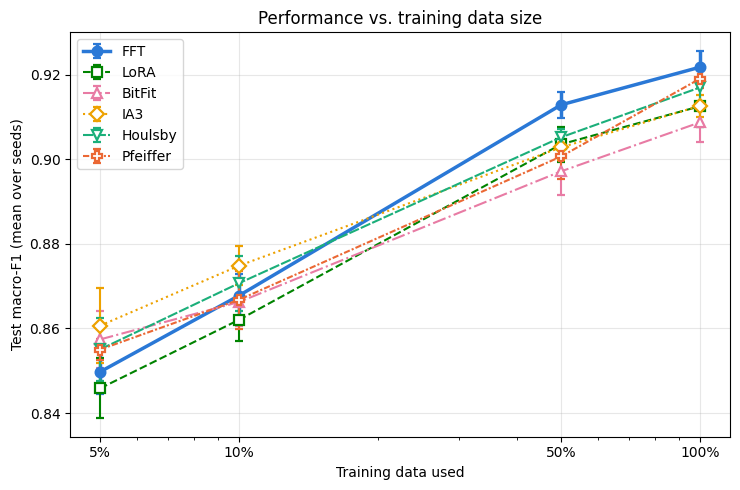

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in METHODS:
    sub = summary.xs(m, level="method").reindex(SIZES)
    ax.errorbar(SIZES, sub["f1_mean"], yerr=sub["f1_std"],
            marker=MARKERS[m], markersize=7, markerfacecolor="white" if m != "FFT" else COLORS[m],
            markeredgewidth=1.6, linestyle=LINESTYLES[m], capsize=3, color=COLORS[m], label=m,
            linewidth=2.5 if m == "FFT" else 1.5)
ax.set_xscale("log")
ax.set_xticks(SIZES); ax.set_xticklabels([f"{s}%" for s in SIZES])
ax.set(xlabel="Training data used", ylabel="Test macro-F1 (mean over seeds)", title="Performance vs. training data size")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
savefig(fig, "f1_vs_data_size")
plt.show()

## Gap to FFT by data size
Mean paired difference (PEFT - FFT) with 95% confidence interval. Intervals that exclude zero are the clear differences;
a gap that shrinks or flips at 10% would be the low-resource finding.

saved gap_to_fft_by_data_size.png / .pdf


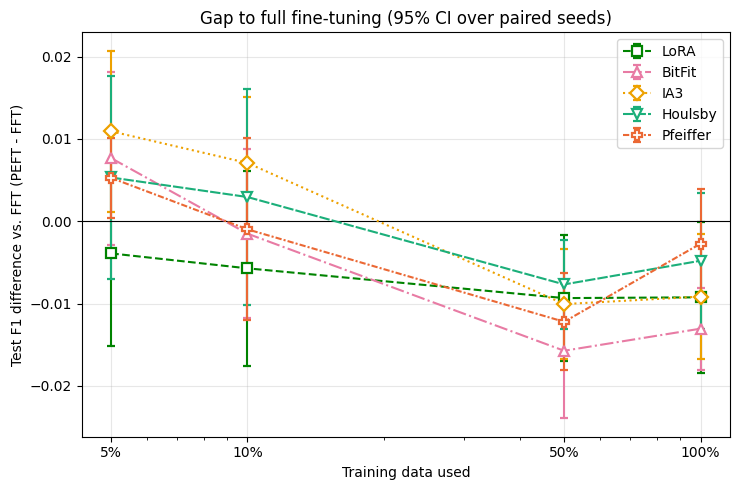

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for m in METHODS[1:]:
    sub = stat_df[stat_df["method"] == m].set_index("data_size").reindex(SIZES)
    yerr = [sub["mean_diff"] - sub["ci_low"], sub["ci_high"] - sub["mean_diff"]]
    ax.errorbar(SIZES, sub["mean_diff"], yerr=yerr,
            marker=MARKERS[m], markersize=7, markerfacecolor="white" if m != "FFT" else COLORS[m],
            markeredgewidth=1.6, linestyle=LINESTYLES[m], capsize=3, color=COLORS[m], label=m,
            linewidth=2.5 if m == "FFT" else 1.5)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks(SIZES); ax.set_xticklabels([f"{s}%" for s in SIZES])
ax.set(xlabel="Training data used", ylabel="Test F1 difference vs. FFT (PEFT - FFT)",
       title="Gap to full fine-tuning (95% CI over paired seeds)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
savefig(fig, "gap_to_fft_by_data_size")
plt.show()

## Performance vs. parameter efficiency (100% data)
Log-scale x-axis (trainable % spans four orders of magnitude). Dashed line = FFT's F1.

saved performance_efficiency_tradeoff_100.png / .pdf


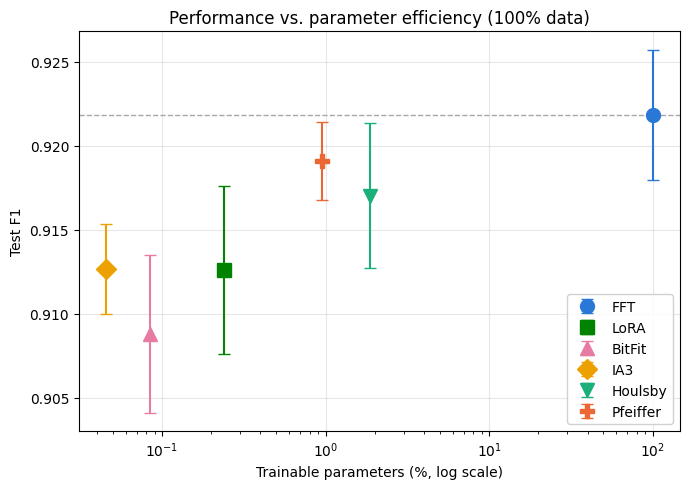

In [12]:
s100 = summary.loc[100]
fig, ax = plt.subplots(figsize=(7, 5))
for m in METHODS:
    r = s100.loc[m]
    ax.errorbar(r["trainable_pct"], r["f1_mean"], yerr=r["f1_std"], fmt=MARKERS[m], markersize=10,
                capsize=4, color=COLORS[m], label=m)
ax.axhline(s100.loc["FFT", "f1_mean"], color="gray", linestyle="--", linewidth=1, alpha=0.7, zorder=0)
ax.set_xscale("log")
ax.set(xlabel="Trainable parameters (%, log scale)", ylabel="Test F1",
       title="Performance vs. parameter efficiency (100% data)")
ax.legend(loc="lower right", framealpha=0.9); ax.grid(alpha=0.3)
plt.tight_layout()
savefig(fig, "performance_efficiency_tradeoff_100")
plt.show()

## Validation vs. test generalization gap
Best validation F1 minus test F1, per method, at each data size.

saved val_test_gap_by_size.png / .pdf


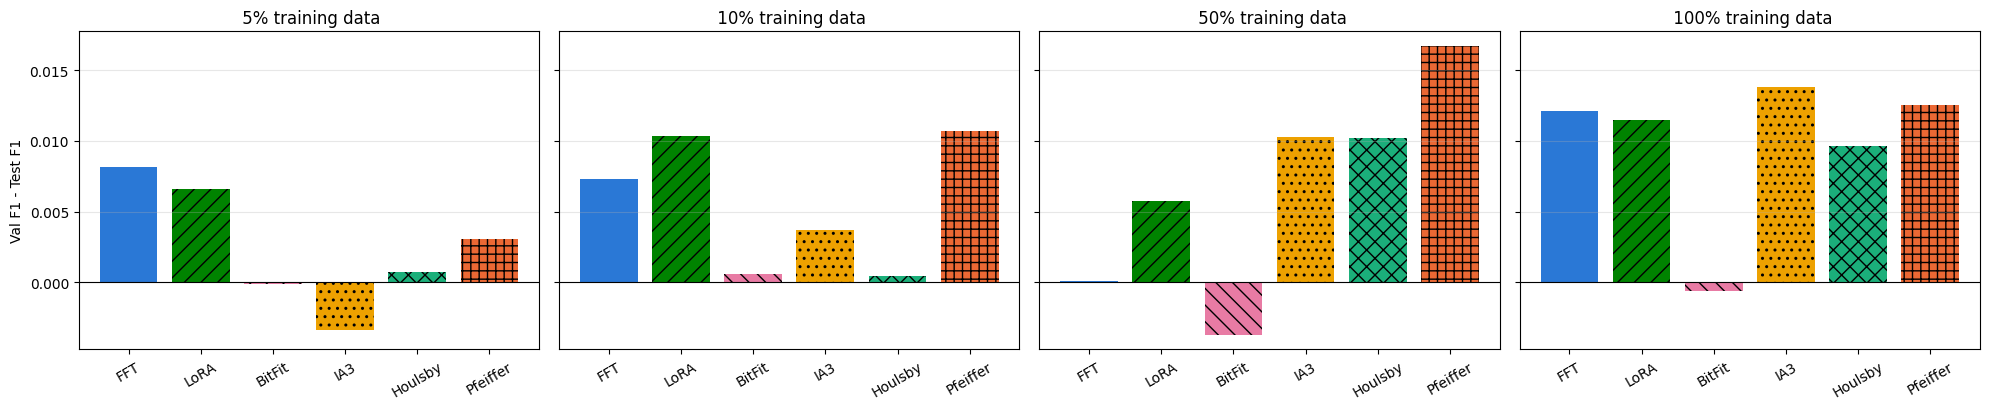

In [13]:
fig, axes = plt.subplots(1, len(SIZES), figsize=(5 * len(SIZES), 4.2), sharey=True)
for ax, size in zip(axes, SIZES):
    gaps = [summary.loc[(size, m), "val_test_gap"] for m in METHODS]
    bars = ax.bar(METHODS, gaps, color=[COLORS[m] for m in METHODS])
    for bar, m in zip(bars, METHODS):
        bar.set_hatch(HATCHES[m])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f" {size}% training data")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Val F1 - Test F1")
plt.tight_layout()
savefig(fig, "val_test_gap_by_size")
plt.show()

## Efficiency (100% data)
Trainable parameters, peak VRAM, and training time per run.

saved efficiency_100.png / .pdf


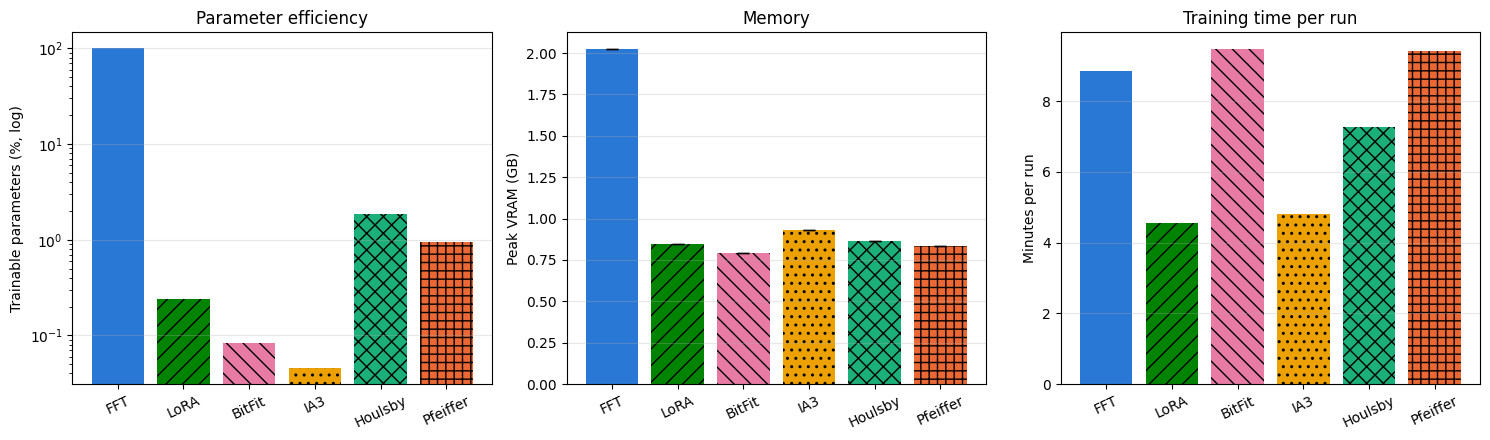

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
bars0 = axes[0].bar(METHODS, [s100.loc[m, "trainable_pct"] for m in METHODS], color=[COLORS[m] for m in METHODS])
for bar, m in zip(bars0, METHODS):
    bar.set_hatch(HATCHES[m])
axes[0].set_yscale("log"); axes[0].set(ylabel="Trainable parameters (%, log)", title="Parameter efficiency")

bars1 = axes[1].bar(METHODS, [s100.loc[m, "vram_mean"] for m in METHODS],
            yerr=[s100.loc[m, "vram_std"] for m in METHODS], capsize=4, color=[COLORS[m] for m in METHODS])
for bar, m in zip(bars1, METHODS):
    bar.set_hatch(HATCHES[m])
axes[1].set(ylabel="Peak VRAM (GB)", title="Memory")

bars2 = axes[2].bar(METHODS, [s100.loc[m, "time_mean_min"] for m in METHODS], color=[COLORS[m] for m in METHODS])
for bar, m in zip(bars2, METHODS):
    bar.set_hatch(HATCHES[m])
axes[2].set(ylabel="Minutes per run", title="Training time per run")

for ax in axes:
    ax.tick_params(axis="x", rotation=25); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
savefig(fig, "efficiency_100")
plt.show()

## Confusion matrices
Pooled over all seeds per method, at 100% and at 10% of the training data.

saved confusion_matrices_100.png / .pdf


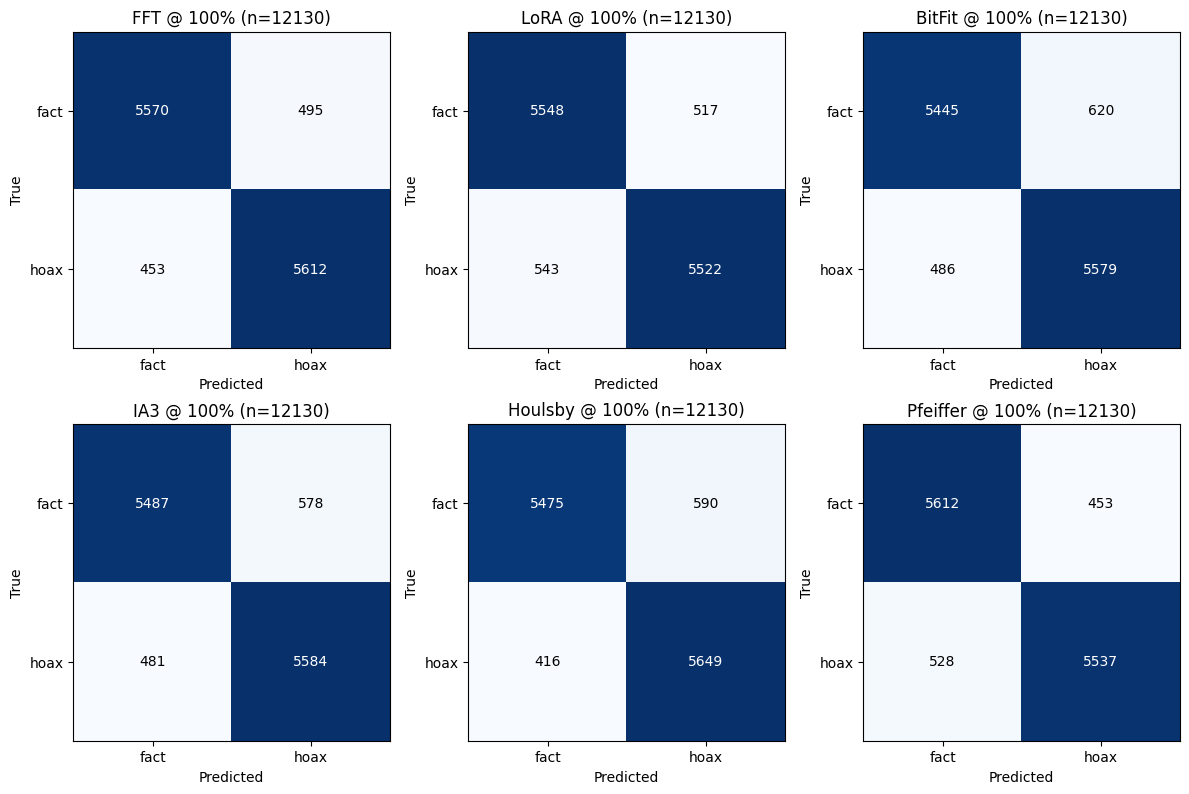

saved confusion_matrices_10.png / .pdf


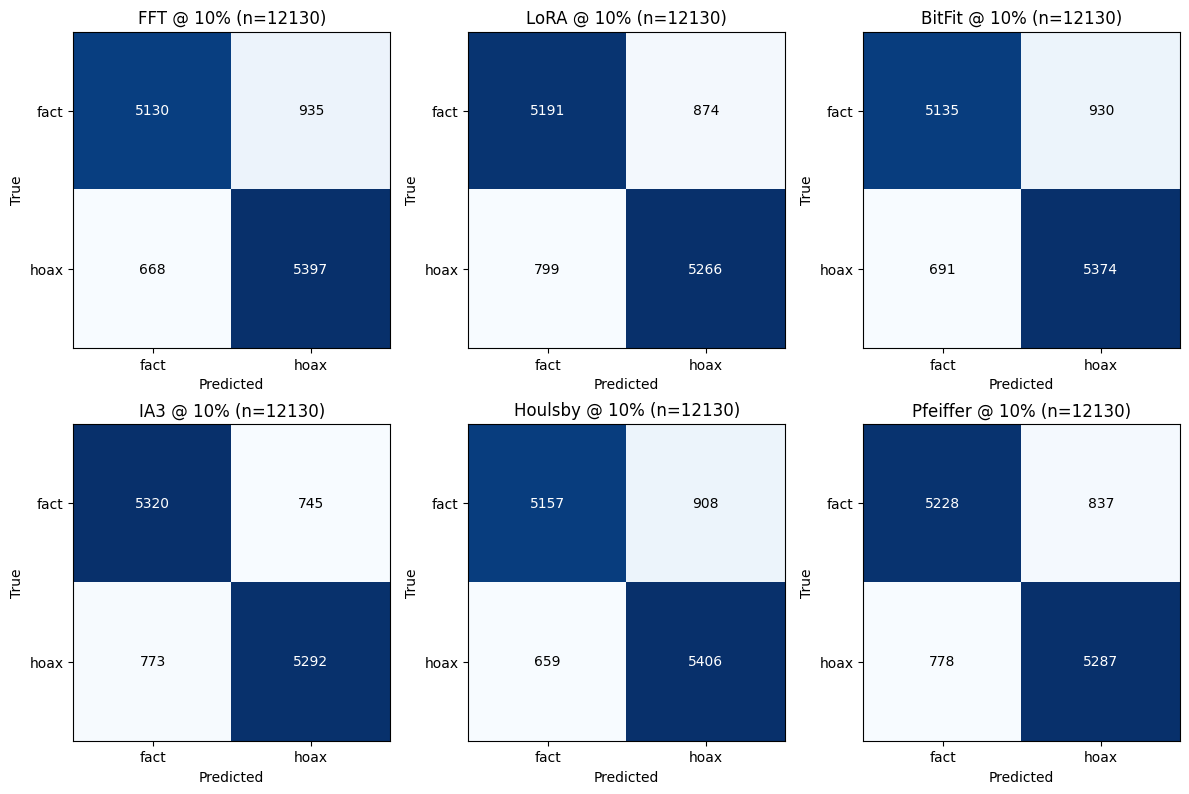

In [15]:
def plot_cms(size):
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, m in zip(axes.flat, METHODS):
        sub = predictions[(predictions["method"] == m) & (predictions["data_size"] == size)]
        if sub.empty:
            ax.set_title(f"{m} (no data)"); ax.axis("off"); continue
        cm = pd.crosstab(sub["true_label"], sub["predicted_label"]).reindex(
            index=[0, 1], columns=[0, 1], fill_value=0).values
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0, 1]); ax.set_xticklabels([ID2LABEL[0], ID2LABEL[1]])
        ax.set_yticks([0, 1]); ax.set_yticklabels([ID2LABEL[0], ID2LABEL[1]])
        ax.set(xlabel="Predicted", ylabel="True", title=f"{m} @ {size}% (n={cm.sum()})")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    savefig(fig, f"confusion_matrices_{size}")
    plt.show()

plot_cms(100)
plot_cms(10)

## Training curves
Validation F1 vs. step, first seed, at 100% and 10% data (evaluation every 531 steps).

saved training_curves_100_vs_10.png / .pdf


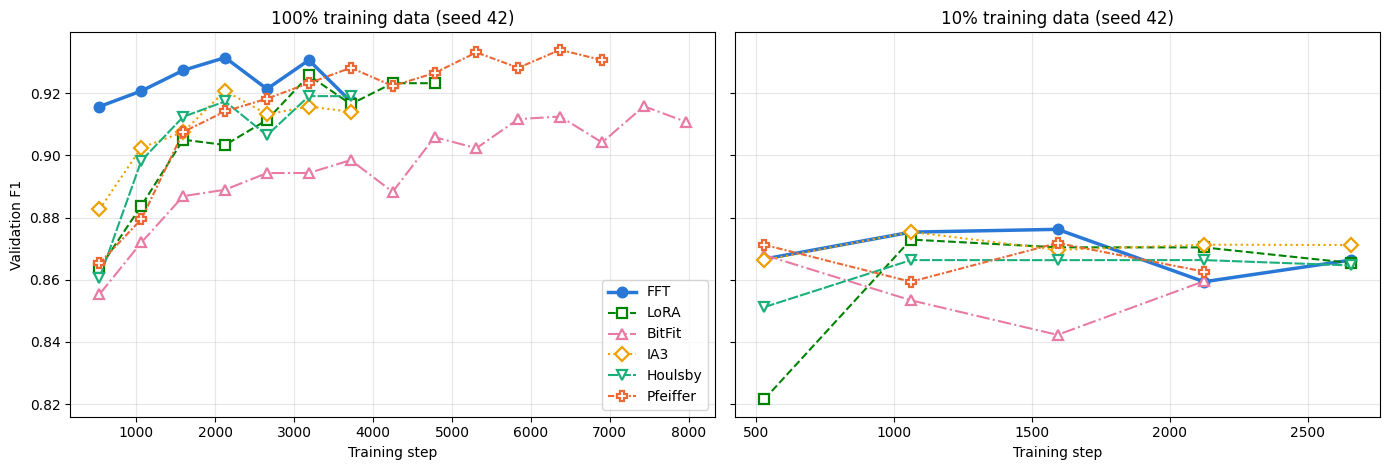

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, size in zip(axes, [100, 10]):
    for m in METHODS:
        path = f"{LOGS_DIR}/{run_key(m, size, SEEDS[0], TAG_FOR_METHOD[m])}_history.json"
        if not os.path.exists(path):
            print(f"no history for {m} @ {size}%")
            continue
        with open(path) as f:
            h = json.load(f)
        ev = [(e["step"], e["eval_f1"]) for e in h if "eval_f1" in e]
        if ev:
            ax.plot(*zip(*ev),
            marker=MARKERS[m], markersize=7, markerfacecolor="white" if m != "FFT" else COLORS[m],
            markeredgewidth=1.6, linestyle=LINESTYLES[m], color=COLORS[m], label=m,
            linewidth=2.5 if m == "FFT" else 1.5)
    ax.set(xlabel="Training step", title=f"{size}% training data (seed {SEEDS[0]})")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Validation F1")
axes[0].legend()
plt.tight_layout()
savefig(fig, "training_curves_100_vs_10")
plt.show()

## Export for the paper
Summary and statistics tables as CSV, plus a markdown version of the 100%-data summary.

In [18]:
summary.round(4).to_csv(f"{FIGURES_DIR}/summary_all_sizes.csv")
stat_df.round(4).to_csv(f"{FIGURES_DIR}/stats_vs_fft.csv", index=False)

cols = ["n_seeds", "val_f1_mean", "val_f1_std", "f1_mean", "f1_std", "acc_mean", "acc_std",
        "trainable_pct", "vram_mean", "time_mean_min", "pct_of_fft_f1", "params_reduction_x", "val_test_gap"]
print(summary.loc[100][cols].round(4).to_markdown())
print()
print("Files in", FIGURES_DIR)
for f in sorted(os.listdir(FIGURES_DIR)):
    print(" -", f)

| method   |   n_seeds |   val_f1_mean |   val_f1_std |   f1_mean |   f1_std |   acc_mean |   acc_std |   trainable_pct |   vram_mean |   time_mean_min |   pct_of_fft_f1 |   params_reduction_x |   val_test_gap |
|:---------|----------:|--------------:|-------------:|----------:|---------:|-----------:|----------:|----------------:|------------:|----------------:|----------------:|---------------------:|---------------:|
| FFT      |         5 |        0.934  |       0.0038 |    0.9218 |   0.0039 |     0.9218 |    0.0039 |        100      |      2.0232 |          8.8633 |        100      |               1      |         0.0121 |
| LoRA     |         5 |        0.9241 |       0.0043 |    0.9126 |   0.005  |     0.9126 |    0.005  |          0.2377 |      0.8478 |          4.557  |         98.9971 |             419.777  |         0.0115 |
| BitFit   |         5 |        0.9082 |       0.0081 |    0.9088 |   0.0047 |     0.9088 |    0.0047 |          0.0839 |      0.789  |          9.4713 